# Scaling with a Dask cluster 
<style>
.scibtn {
  background-color: #04AA6D;
  color: white;
  font-size: 15px;
  padding: 12px;
  border: none;
  border-radius: 5px;
  cursor: pointer;
}
.techbtn {
  background-color: #0407aaff;
  color: white;
  font-size: 15px;
  padding: 12px;
  border: none;
  border-radius: 5px;
  cursor: pointer;
}
.databtn {
  background-color: #edfd03ff;
  color: black;
  font-size: 15px;
  padding: 12px;
  border: none;
  border-radius: 5px;
  cursor: pointer;
}

</style>

<button class="techbtn">Technical</button> &nbsp; <button class="databtn">Satellite</button>

__Description & purpose__: This Notebook is designed to showcase the use of Dask tools and the ability to scale processing on the EODH. It is assumed that this notebook will be run within the Notebook Service on the Hub and that **you have requested and set up a distributed Dask cluster on Kubernetes**. If the cluster is not in place then this notebook will not sccessfully complete. 

For every Sentinel-2 ARD scene over a small area of the UK for a given time period we will read the red and near-infrared bands and compute the mean Normalised Difference Vegetation Index (NDVI), a common EO data processing pattern. Each scene is implemented as an independent task i.e. open a remote GeoTIFF, read two bands, do a little arithmetic. Most of the processing time goes on waiting for data to arrive over the network and that makes it a good fit for Dask: instead of doing the scenes one after another we can hand them to a cluster of workers that each process several scenes at the same time.

In [ ]:
# Install only missing packages on EODH, rather than upgrading the whole environment.
%pip install pyeodh folium

In [18]:
import threading
import time

import numpy as np
import pandas as pd
import rasterio
import pyeodh
import folium
import geopandas as gpd
import matplotlib.pyplot as plt

from rasterio.windows import Window
from IPython.display import HTML, display
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Rectangle
from shapely.geometry import Polygon, mapping, shape, box
from dask_kubernetes.operator import KubeCluster

## Settings

In [9]:
# Search settings
BASE_URL = "https://eodatahub.org.uk"
CATALOG_PATH = "public/catalogs/ceda-stac-catalogue"
COLLECTION_ID = "sentinel2_ard"
SEARCH_START = "2024-01-01"
SEARCH_END = "2024-12-31"
BBOX = [-1.40, 51.65, -1.10, 51.85]   # a small area around Oxford (lon/lat)

# Dask cluster settings
NAMESPACE = "ws-dask-uj"
CLUSTER_NAME = "test-cluster"
N_WORKERS = 2
BLOCK_SIZE = 256

# --- Extra settings for this demo ---
N_SCENES = 100                          # maximum scenes to process
WINDOW = 8 * BLOCK_SIZE                # read a 2048 x 2048 pixel (20 km) patch from each scene
RED_BAND, NIR_BAND = 3, 7              # band order in the ARD 'cog' asset: B02,B03,B04,...,B08,...

## Area of interest

In [10]:
# Create rectangular AOI
aoi = gpd.GeoDataFrame(
    {"name": ["Oxford surrounds"]},
    geometry=[box(*BBOX)],
    crs="EPSG:4326",
)

# Calculate map centre from the AOI
centre = aoi.geometry.iloc[0].centroid

# Create interactive map
m = folium.Map(
    location=[centre.y, centre.x],
    zoom_start=10,
    tiles="OpenStreetMap",
)

# Add AOI
folium.GeoJson(
    aoi,
    name="AOI",
    style_function=lambda feature: {
        "color": "red",
        "weight": 2,
        "fillColor": "red",
        "fillOpacity": 0.1,
    },
    tooltip=folium.GeoJsonTooltip(
        fields=["name"],
        aliases=["AOI:"],
    ),
).add_to(m)

folium.LayerControl().add_to(m)

m

## Find the scenes

We search the CEDA STAC catalogue on the EO DataHub and keep just what each task needs:
an ID, a date and the URL of the multi-band surface reflectance GeoTIFF (the `cog` asset).

In [14]:
catalog = pyeodh.Client(base_url=BASE_URL).get_catalog_service()

items = list(
    catalog.search(
        collections=[COLLECTION_ID],
        catalog_paths=[CATALOG_PATH],
        bbox=BBOX,
        start_datetime=SEARCH_START,
        end_datetime=SEARCH_END,
        limit=N_SCENES,
    )
)

scenes = [
    {
        "id": item.id.split(".")[-1],
        "date": item.datetime.date(),
        "href": item.assets["cog"].href,
    }
    for item in items
]

print(f"Found {len(scenes)} scenes")

if scenes:
    print(f"Example:\n  {scenes[0]['id']}\n  {scenes[0]['href']}")

Found 67 scenes
Example:
  S2B_20241219_latn518lonw0008_T30UXC_ORB037_20241219145422_utm30n_osgb
  https://dap.ceda.ac.uk/neodc/sentinel_ard/data/sentinel_2/2024/12/19/S2B_20241219_latn518lonw0008_T30UXC_ORB037_20241219145422_utm30n_osgb_vmsk_sharp_rad_srefdem_stdsref.tif


## Setting up the task: one scene in, one NDVI value out

`process_scene` is ordinary Python that does a number of things. It calculates NDVI, records when it started and finished and if running on a Dask cluster it records which Dask worker and thread it used. When testing the 'series' processing in the workspace the "worker" is recorded as `notebook`.

In [16]:
# Set up GDAL to optimise for cloud interactions
GDAL_ENV = {
    "GDAL_DISABLE_READDIR_ON_OPEN": "EMPTY_DIR",   # don't list remote directories
    "CPL_VSIL_CURL_ALLOWED_EXTENSIONS": ".tif",
    "GDAL_HTTP_MAX_RETRY": "3",
}

def process_scene(scene):
    """Read a central patch of red & NIR from one scene and return its mean NDVI."""
    try:
        from distributed import get_worker
        where = get_worker().name
    except (ImportError, ValueError):
        where = "notebook"

    start = time.time()
    with rasterio.Env(**GDAL_ENV), rasterio.open(scene["href"]) as src:
        row0 = (src.height - WINDOW) // 2 // BLOCK_SIZE * BLOCK_SIZE   # align to 256-pixel tiles
        col0 = (src.width - WINDOW) // 2 // BLOCK_SIZE * BLOCK_SIZE
        red, nir = src.read([RED_BAND, NIR_BAND], window=Window(col0, row0, WINDOW, WINDOW)).astype("float32")

    valid = (red > 0) & (nir > 0)
    ndvi = (nir[valid] - red[valid]) / (nir[valid] + red[valid])

    return {
        "id": scene["id"],
        "date": scene["date"],
        "mean_ndvi": float(ndvi.mean()) if ndvi.size else np.nan,
        "worker": str(where),
        "thread": threading.current_thread().name,
        "start": start,
        "end": time.time(),
    }

# Quick check on one scene
#process_scene(scenes[0])

## Run in series (the normal notebook way)

In [17]:
t0 = time.time()
serial_results = [process_scene(s) for s in scenes]
serial_time = time.time() - t0
print(f"Serial: {len(scenes)} scenes in {serial_time:.1f} s")

Serial: 67 scenes in 302.2 s


## Start the Dask cluster

`KubeCluster` launches worker pods in your workspace. Each worker has 2 CPUs, so it runs 2 tasks at once (2 threads). With 2 workers that gives **4 tasks in flight** at any moment. If you require more processing capability then this will be discussed with the platform Admins ahead of the cluster being initialised. 

_Note_: Dask dashboard is currently unavailable on EODH. If there is enough demand for this function, it can be implemented as part of a future development cycle.

In [19]:
cluster = KubeCluster(
    name=CLUSTER_NAME,
    namespace=NAMESPACE,
    n_workers=N_WORKERS,
    image="public.ecr.aws/eodh/eodh-default-notebook:python-3.13-2026.02.3",
    resources={
        "requests": {"memory": "4Gi", "cpu": "2"},
        "limits": {"memory": "4Gi", "cpu": "2"},
    },
)


Output()

In [20]:
client = cluster.get_client()
client.wait_for_workers(N_WORKERS)

print(client)
print("Workers:", len(client.scheduler_info()["workers"]))
print("Dashboard:", client.dashboard_link)

/opt/conda/lib/python3.13/site-packages/distributed/client.py:1595: VersionMismatchWarning: Mismatched versions found

+-------------+-----------------+-----------------+-----------------+
| Package     | Client          | Scheduler       | Workers         |
+-------------+-----------------+-----------------+-----------------+
| dask        | 2026.8.0        | 2026.1.2        | 2026.1.2        |
| distributed | 2026.8.0        | 2026.1.2        | 2026.1.2        |
| msgpack     | 1.2.3           | 1.1.2           | 1.1.2           |
| numpy       | 2.5.3           | 2.3.5           | 2.3.5           |
| pandas      | 3.0.6           | 3.0.1           | 3.0.1           |
| python      | 3.13.15.final.0 | 3.13.12.final.0 | 3.13.12.final.0 |
| tornado     | 6.5.10          | 6.5.4           | 6.5.4           |
+-------------+-----------------+-----------------+-----------------+
  warnings.warn(version_module.VersionMismatchWarning(msg[0]["warning"]))


<Client: 'tcp://10.0.81.194:8786' processes=1 threads=2, memory=4.00 GiB>
Workers: 2
Dashboard: http://test-cluster-scheduler.ws-dask-uj:8787/status


## Run in parallel on Dask

The only change from the serial version: instead of a `for` loop, `client.map` sends `process_scene` and each scene to the cluster, and `client.gather` collects the answers.

In [21]:
t0 = time.time()
futures = client.map(process_scene, scenes, pure=False)   # send one task per scene
dask_results = client.gather(futures)                     # wait for all of them
dask_time = time.time() - t0

print(f"Serial: {serial_time:6.1f} s")
print(f"Dask  : {dask_time:6.1f} s   ->  {serial_time / dask_time:.1f}x faster")

Serial:  302.2 s
Dask  :   83.8 s   ->  3.6x faster


## Comparing processing speeds

Each white vertical bar in the chart below represents when one scene was processed. In the serial run every bar sits on one lane, end to end. On Dask the same bars are spread across the worker threads, so they overlap in time. This means that the whole job finishes sooner when scaled to use multiple worker threads. From this we can start to see what the impact would be of increasing the size of the cluster (i.e. increasing the number of workers and threads).

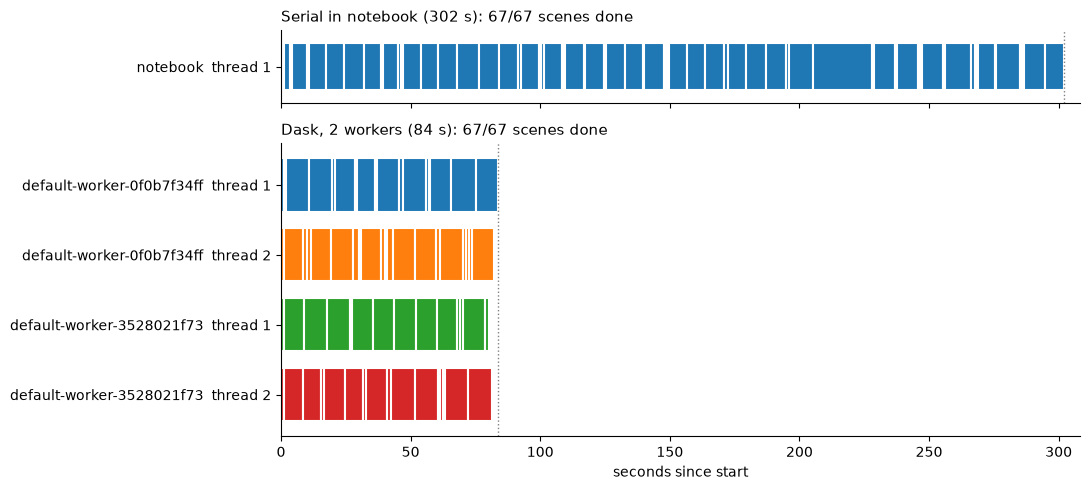

In [22]:
def to_frame(results):
    """Turn task records into a table with one 'lane' per worker thread and times in seconds."""
    
    df = pd.DataFrame(results)
    t_zero = df["start"].min()
    df["start"] -= t_zero
    df["end"] -= t_zero
    
    # Give each thread on each worker a simple, readable lane name
    df["slot"] = df.groupby("worker")["thread"].transform(lambda t: pd.factorize(t)[0] + 1)
    df["lane"] = df["worker"].str.replace(f"{CLUSTER_NAME}-", "", regex=False) + "  thread " + df["slot"].astype(str)
    return df.sort_values("lane")

serial_df = to_frame(serial_results)
dask_df = to_frame(dask_results)
t_max = max(serial_df["end"].max(), dask_df["end"].max())

def draw_timeline(ax, df, title, now=None):
    """Draw tasks as bars; if `now` is given, only show progress up to that moment."""
    
    ax.clear()
    lanes = list(dict.fromkeys(df["lane"]))
    colours = plt.cm.tab10(np.arange(len(lanes)) % 10)
    for i, lane in enumerate(lanes):
        for _, task in df[df["lane"] == lane].iterrows():
            end = task["end"] if now is None else min(task["end"], now)
            if end <= task["start"]:
                continue
            done = now is None or now >= task["end"]
            ax.add_patch(Rectangle((task["start"], i - 0.38), end - task["start"], 0.76,
                                   facecolor=colours[i], alpha=1.0 if done else 0.45,
                                   edgecolor="white", linewidth=1.5))
    n_done = len(df) if now is None else int((df["end"] <= now).sum())
    finish = df["end"].max()
    ax.set_yticks(range(len(lanes)), lanes)
    ax.set_ylim(-0.6, len(lanes) - 0.4)
    ax.set_xlim(0, t_max * 1.02)
    ax.invert_yaxis()
    ax.set_title(f"{title}: {n_done}/{len(df)} scenes done", loc="left", fontsize=11)
    if now is None or now >= finish:
        ax.axvline(finish, color="grey", ls=":", lw=1)   # mark when this run finished
    if now is not None:
        ax.axvline(min(now, t_max), color="crimson", lw=1.5)
    ax.spines[["top", "right"]].set_visible(False)

fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True,
                         gridspec_kw={"height_ratios": [1, max(1, dask_df["lane"].nunique())]})
draw_timeline(axes[0], serial_df, f"Serial in notebook ({serial_time:.0f} s)")
draw_timeline(axes[1], dask_df, f"Dask, {N_WORKERS} workers ({dask_time:.0f} s)")
axes[1].set_xlabel("seconds since start")
plt.tight_layout()
plt.show()

### Animate the time component

Both runs can be replayed side by side on the same clock. The red line represents "now" and the playback is a speeded up version of what happened.

In [23]:
N_FRAMES = 80
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True,
                         gridspec_kw={"height_ratios": [1, max(1, dask_df["lane"].nunique())]})

def update(frame):
    now = t_max * frame / (N_FRAMES - 1)
    draw_timeline(axes[0], serial_df, "Serial in notebook", now=now)
    draw_timeline(axes[1], dask_df, f"Dask, {N_WORKERS} workers", now=now)
    axes[1].set_xlabel("seconds since start")
    fig.suptitle(f"t = {now:5.1f} s", x=0.98, ha="right", fontsize=11)

update(N_FRAMES - 1)                        # draw once so the layout can size the labels
fig.tight_layout(rect=[0, 0, 1, 0.95])      # leave room for the clock at the top
anim = FuncAnimation(fig, update, frames=N_FRAMES, interval=100)
plt.close(fig)
display(HTML(anim.to_jshtml()))

# Optional: save as a gif
# anim.save("dask_race.gif", writer="pillow", fps=10)   # uncomment to save a GIF

## NDVI output

Both methods give identical numbers; Dask just gets there sooner. Cloudy scenes pull the mean NDVI down, so expect some scatter around the seasonal cycle.

Serial and Dask results match: True


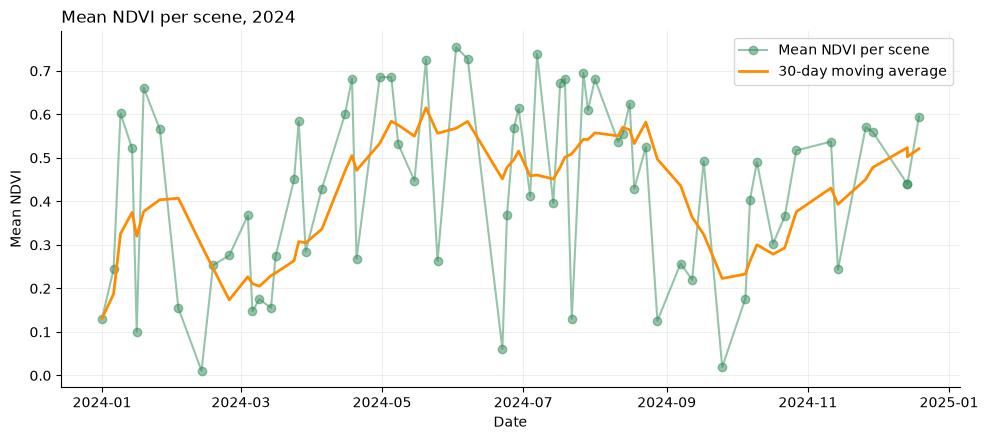

In [27]:
results = pd.DataFrame(dask_results).sort_values("date")
results["date"] = pd.to_datetime(results["date"])

check = pd.DataFrame(serial_results).set_index("id")["mean_ndvi"]

print(
    "Serial and Dask results match:",
    np.allclose(
        results.set_index("id")["mean_ndvi"],
        check.loc[results["id"]],
        equal_nan=True,
    ),
)

# Calculate 30-day moving average
results["moving_avg"] = (
    results.set_index("date")["mean_ndvi"]
    .rolling("30D", min_periods=1)
    .mean()
    .to_numpy()
)

# Convert dates to elapsed days for fitting
x = (results["date"] - results["date"].min()).dt.days.to_numpy()
y = results["mean_ndvi"].to_numpy()

# Smooth date axis 
x_smooth = np.linspace(x.min(), x.max(), 300)
dates_smooth = results["date"].min() + pd.to_timedelta(
    x_smooth, unit="D"
)

# Plot
fig, ax = plt.subplots(figsize=(10, 4.5))

ax.plot(
    results["date"], results["mean_ndvi"],
    "o-", color="seagreen", alpha=0.5,
    label="Mean NDVI per scene",
)

ax.plot(
    results["date"], results["moving_avg"],
    color="darkorange", linewidth=2,
    label="30-day moving average",
)

ax.set_ylabel("Mean NDVI")
ax.set_xlabel("Date")
ax.set_title(f"Mean NDVI per scene, {SEARCH_START[:4]}", loc="left")
ax.legend()
ax.grid(alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

## IMPORTANT: close the Dask cluster

In [28]:
# Tidy up: release the worker pods when you are done
client.close()
cluster.close()